# SNNTraffic: Spiking Neural Networks for Adaptive Traffic Signal Control

This notebook implements and compares two Deep Reinforcement Learning agents for adaptive traffic signal control in the SUMO simulator using a **2x2 grid network** (4 intersections):

- **ANN-DQN**: A baseline Deep Q-Network using a standard Artificial Neural Network
- **Spiking-DQN**: A proposed Spiking Neural Network-based DQN

Both agents use a **centralized architecture**: observations from all 4 traffic signals are concatenated, and the agent outputs actions for all signals simultaneously.

Both are compared against a **Fixed-Time** baseline controller with staggered phase offsets.

In [1]:
import os

# Detect if running on Google Colab and install SUMO + dependencies
if os.getenv("COLAB_RELEASE_TAG"):
    print("Running on Colab")
    print("Installing SUMO and dependencies...")
    !add-apt-repository ppa:sumo/stable -y > /dev/null 2>&1
    !apt-get update -q > /dev/null 2>&1
    !apt-get install sumo sumo-tools -y > /dev/null 2>&1
    os.environ['SUMO_HOME'] = "/usr/share/sumo"

    !pip install sumo-rl gymnasium torch matplotlib numpy snntorch -q
    print("Environment configured successfully!")
else:
    print("Not running on Colab")
    import sumo
    # Ensure SUMO_HOME dynamically points to the pip-installed SUMO path
    os.environ['SUMO_HOME'] = sumo.SUMO_HOME

Not running on Colab


## Imports, Reproducibility, and Configuration

In [ ]:
import random
from collections import deque
from dataclasses import dataclass
import numpy as np
import matplotlib.pyplot as plt
import time

import torch
import torch.nn as nn
import torch.optim as optim

import sumo_rl
from sumo_rl import SumoEnvironment

# ---------------------------------------------------------------------------
# Reproducibility
# ---------------------------------------------------------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Computation device: {device}")

# ---------------------------------------------------------------------------
# Hyperparameters
# ---------------------------------------------------------------------------
@dataclass
class Config:
    # RL parameters
    episodes: int = 40            # Training episodes (short for testing; increase for real runs)
    sim_seconds: int = 3600       # Simulation seconds per episode (1 simulated hour)
    delta_time: int = 5           # Agent decides every 5 simulation seconds
    batch_size: int = 64
    gamma: float = 0.99           # Discount factor
    lr: float = 1e-3              # Learning rate
    eps_start: float = 1.0        # Initial exploration rate
    eps_end: float = 0.05         # Minimum exploration rate
    eps_decay: float = 0.90       # Epsilon decay rate per episode
    target_update: int = 5        # Target network update frequency (episodes)
    replay_capacity: int = 10000  # Replay buffer capacity
    snn_num_steps: int = 8        # SNN temporal window
    snn_beta: float = 0.9         # SNN membrane decay rate

    # Network architecture
    hidden_dim: int = 128         # Hidden layer size

    # File paths
    ann_model_path: str = "ann_dqn_model.pth"
    snn_model_path: str = "snn_dqn_model.pth"
    ann_plot_path: str = "training_ann_baseline.png"
    comparison_plot_path: str = "comparison_ann_vs_snn.png"

cfg = Config()

# ---------------------------------------------------------------------------
# Seed offsets for reproducibility
# Both agents see the SAME sequence of episode seeds for a fair comparison.
# ---------------------------------------------------------------------------
TRAIN_SEED_OFFSET = 1000       # Shared offset for training episodes (ANN + SNN)
EVAL_SEED = 9999               # Fixed seed for the single evaluation run
FIXED_TIME_SEED = 5000         # Base offset for fixed-time baseline episodes

# ---------------------------------------------------------------------------
# ---------------------------------------------------------------------------

# ---------------------------------------------------------------------------
# Locate SUMO-RL network and route files (2x2 grid)
# ---------------------------------------------------------------------------
NET_FILE = os.path.join(
    sumo_rl.__path__[0], 'nets', '2x2grid', '2x2.net.xml'
)
ROUTE_FILE = os.path.join(
    sumo_rl.__path__[0], 'nets', '2x2grid', '2x2.rou.xml'
)

Computation device: cuda


---
## Environment Helpers

The 2x2 grid has 4 traffic signals (IDs: 1, 2, 5, 6). Each TS has 4 green phases and 8 incoming lanes.

Observation per TS: `[phase_one_hot(4), min_green(1), density(8), queue(8)]` = 21 dimensions.
Concatenated observation for all 4 TS: **84 dimensions**.

Action per TS: discrete 0-3 (select green phase). The centralized agent outputs 4 actions (one per TS).

**Important**: In multi-agent mode (`single_agent=False`), SUMO-RL returns:
- `reset()` -> just the observations dict (no info tuple)
- `step(action)` -> `(obs_dict, rewards_dict, dones_dict, info)`

In [3]:
def make_env(use_gui=False):
    """Create a SUMO 2x2 grid environment (multi-agent)."""
    return SumoEnvironment(
        net_file=NET_FILE,
        route_file=ROUTE_FILE,
        out_csv_name=None,
        use_gui=use_gui,
        num_seconds=cfg.sim_seconds,
        delta_time=cfg.delta_time,
        single_agent=False,  # Multi-agent: returns dicts with ts_id keys
    )


def concatenate_observations(obs_dict):
    """Concatenate dict of observations into a single flat vector."""
    return np.concatenate([obs_dict[ts_id] for ts_id in sorted(obs_dict.keys())])


# We'll set these lazily when first needed
env = None
num_agents = None
obs_dim_per_agent = None
act_dim_per_agent = None
total_obs_dim = None
total_act_dim = None
ts_ids_sorted = None

def init_env_params():
    """Probe the environment once to determine dimensions."""
    global env, num_agents, obs_dim_per_agent, act_dim_per_agent
    global total_obs_dim, total_act_dim, ts_ids_sorted
    if env is None:
        env = SumoEnvironment(
            net_file=NET_FILE,
            route_file=ROUTE_FILE,
            out_csv_name=None,
            use_gui=False,
            num_seconds=1,
            delta_time=cfg.delta_time,
            single_agent=False,
        )
        ts_ids_sorted = sorted(env.ts_ids)
        num_agents = len(ts_ids_sorted)
        ts_id = ts_ids_sorted[0]
        obs_dim_per_agent = env.observation_spaces(ts_id).shape[0]
        act_dim_per_agent = env.action_spaces(ts_id).n
        total_obs_dim = num_agents * obs_dim_per_agent
        total_act_dim = num_agents * act_dim_per_agent
        env.close()
        env = None
        print(f"2x2 Grid: {num_agents} traffic signals")
        print(f"  Per-agent observation dim: {obs_dim_per_agent}")
        print(f"  Per-agent action dim: {act_dim_per_agent}")
        print(f"  Total concatenated obs dim: {total_obs_dim}")
        print(f"  Total action dim: {total_act_dim}")

init_env_params()

 Retrying in 1 seconds
Step #0.00 (0ms ?*RT. ?UPS, TraCI: 5ms, vehicles TOT 0 ACT 0 BUF 0)                      
2x2 Grid: 4 traffic signals
  Per-agent observation dim: 21
  Per-agent action dim: 4
  Total concatenated obs dim: 84
  Total action dim: 16


---
## ANN-DQN Agent (Baseline)

In [4]:
# ---------------------------------------------------------------------------
# 1. Classical Neural Network Architecture (ANN Baseline)
# ---------------------------------------------------------------------------
class DQN(nn.Module):
    """Standard Deep Q-Network with two hidden layers.
    
    Takes concatenated observations from all agents, outputs Q-values
    for all agents concatenated (num_agents * action_dim_per_agent).
    """
    def __init__(self, state_dim, action_dim, hidden_dim=128):
        super(DQN, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, action_dim)
        )

    def forward(self, x):
        return self.net(x)

# ---------------------------------------------------------------------------
# 2. Experience Replay Buffer
# ---------------------------------------------------------------------------
class ReplayBuffer:
    """Circular buffer for storing and sampling experience tuples."""
    def __init__(self, capacity=10000):
        self.buffer = deque(maxlen=capacity)

    def push(self, state, action, reward, next_state, done):
        self.buffer.append((state, action, reward, next_state, done))

    def sample(self, batch_size):
        state, action, reward, next_state, done = zip(*random.sample(self.buffer, batch_size))
        return (
            torch.FloatTensor(np.array(state)).to(device),
            torch.LongTensor(np.array(action)).to(device),
            torch.FloatTensor(np.array(reward)).to(device),
            torch.FloatTensor(np.array(next_state)).to(device),
            torch.FloatTensor(np.array(done)).to(device),
        )

    def __len__(self):
        return len(self.buffer)

In [5]:
class DQNAgent:
    """Centralized Deep Q-Network agent for multi-agent traffic control.
    
    Takes concatenated observations from all traffic signals and outputs
    Q-values for all actions across all signals.
    Uses additive Q-value decomposition: Q_total(s, a_1..a_N) = sum_i Q_i(s, a_i).
    """
    def __init__(self, state_dim, action_dim, hidden_dim=128):
        self.action_dim = action_dim  # total action dim (num_agents * act_per_agent)
        self.epsilon = cfg.eps_start

        # Policy and target networks
        self.policy_net = DQN(state_dim, action_dim, hidden_dim=hidden_dim).to(device)
        self.target_net = DQN(state_dim, action_dim, hidden_dim=hidden_dim).to(device)
        self.target_net.load_state_dict(self.policy_net.state_dict())
        self.target_net.eval()

        self.optimizer = optim.Adam(self.policy_net.parameters(), lr=cfg.lr)
        self.loss_fn = nn.SmoothL1Loss()  # Huber loss for stability
        self.memory = ReplayBuffer(capacity=cfg.replay_capacity)

    def select_action(self, concat_state, evaluate=False):
        """Select actions for all agents via epsilon-greedy or argmax.
        
        Returns:
            flat_actions: 1D array of actions per agent (length num_agents)
        """
        if not evaluate and random.random() < self.epsilon:
            # Random action for each agent
            return np.array([random.randrange(act_dim_per_agent) for _ in range(num_agents)])

        with torch.no_grad():
            state_tensor = torch.FloatTensor(concat_state).unsqueeze(0).to(device)
            q_values_all = self.policy_net(state_tensor)  # (1, total_act_dim)
            # Reshape to (1, num_agents, act_per_agent) and argmax over last dim
            q_reshaped = q_values_all.view(1, num_agents, act_dim_per_agent)
            flat_actions = q_reshaped.argmax(dim=-1).squeeze(0).cpu().numpy()  # (num_agents,)
            return flat_actions

    def update(self):
        """Perform one gradient descent step on a minibatch."""
        if len(self.memory) < cfg.batch_size:
            return 0.0

        states, actions, rewards, next_states, dones = self.memory.sample(cfg.batch_size)
        # actions shape: (batch_size, num_agents)

        # Q-values shape: (batch, total_act_dim) = (batch, num_agents * act_dim_per_agent)
        q_all = self.policy_net(states)
        q_reshaped = q_all.view(-1, num_agents, act_dim_per_agent)  # (batch, num_agents, act_per_agent)
        
        # For each agent, index the Q-value for its chosen action and sum
        actions = actions.long().unsqueeze(-1)  # (batch, num_agents, 1)
        curr_q_per_agent = q_reshaped.gather(2, actions).squeeze(-1)  # (batch, num_agents)
        curr_q = curr_q_per_agent.sum(dim=1)  # (batch,) - sum Q-values across agents

        # Target Q
        with torch.no_grad():
            next_q_all = self.target_net(next_states)
            next_q_reshaped = next_q_all.view(-1, num_agents, act_dim_per_agent)
            # Best action per agent (argmax)
            max_next_q_per_agent = next_q_reshaped.max(dim=-1)[0]  # (batch, num_agents)
            max_next_q = max_next_q_per_agent.sum(dim=1)  # (batch,)
            target_q = rewards + (1 - dones) * cfg.gamma * max_next_q

        loss = self.loss_fn(curr_q, target_q)

        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()

        return loss.item()

    def decay_epsilon(self):
        """Decay exploration rate."""
        self.epsilon = max(cfg.eps_end, self.epsilon * cfg.eps_decay)

---
## Baseline 1: Fixed-Time Controller (Staggered)

Each traffic signal cycles through its 4 phases independently with a staggered offset per intersection.

In [6]:
def evaluate_fixed_time(episodes=3):
    """Evaluate a fixed-time controller with staggered phase offsets.
    
    Each TS cycles through 4 phases. Each phase lasts 6 steps (30s at 5s delta).
    TS are staggered so they start at different phases.
    """
    print("Evaluating Fixed-Time Baseline (staggered)...")
    env = make_env()
    ts_ids = sorted(env.ts_ids)
    phases_per_cycle = 4  # 4 green phases
    steps_per_phase = 6   # 6 steps per phase (30s at 5s delta)
    
    total_waiting_times = []

    for ep in range(episodes):
        obs_dict = env.reset(seed=FIXED_TIME_SEED + ep)
        done = False
        step = 0
        episode_waiting_time = 0
        
        # Stagger: each TS starts at a different phase
        ts_phases = {ts_id: i % phases_per_cycle for i, ts_id in enumerate(ts_ids)}

        while not done:
            # Build actions dict
            actions = {}
            for i, ts_id in enumerate(ts_ids):
                # Change phase every steps_per_phase steps
                if step % steps_per_phase == 0:
                    ts_phases[ts_id] = (ts_phases[ts_id] + 1) % phases_per_cycle
                actions[ts_id] = ts_phases[ts_id]

            # multi-agent step returns (obs_dict, rewards_dict, dones_dict, info)
            obs_dict, rewards_dict, dones_dict, info = env.step(actions)
            done = dones_dict["__all__"]
            episode_waiting_time += info.get('system_total_waiting_time', 0)
            step += 1

        total_waiting_times.append(episode_waiting_time / step)

    env.close()
    avg_wt = np.mean(total_waiting_times)
    print(f"Fixed-Time - Average waiting time: {avg_wt:.2f} s")
    return avg_wt


fixed_baseline_wt = evaluate_fixed_time(episodes=3)

Evaluating Fixed-Time Baseline (staggered)...
 Retrying in 1 seconds
Step #0.00 (0ms ?*RT. ?UPS, TraCI: 3ms, vehicles TOT 0 ACT 0 BUF 0)                      
 Retrying in 1 seconds
Step #3600.00 (0ms ?*RT. ?UPS, TraCI: 16ms, vehicles TOT 1500 ACT 69 BUF 0)               
 Retrying in 1 seconds
Step #3600.00 (0ms ?*RT. ?UPS, TraCI: 15ms, vehicles TOT 1438 ACT 61 BUF 0)               
 Retrying in 1 seconds
Step #3600.00 (0ms ?*RT. ?UPS, TraCI: 19ms, vehicles TOT 1449 ACT 73 BUF 0)               
Fixed-Time - Average waiting time: 1301.03 s


---
## Baseline 2: Train ANN-DQN Agent

In [7]:
# Instantiate environment and agent
env = make_env()
ts_ids_sorted = sorted(env.ts_ids)
num_agents = len(ts_ids_sorted)
obs_dim_per_agent = env.observation_spaces(ts_ids_sorted[0]).shape[0]
act_dim_per_agent = env.action_spaces(ts_ids_sorted[0]).n
total_obs_dim = num_agents * obs_dim_per_agent
total_act_dim = num_agents * act_dim_per_agent

print(f"Environment: {num_agents} agents, obs_dim={total_obs_dim}, act_dim={total_act_dim}")

agent = DQNAgent(total_obs_dim, total_act_dim, hidden_dim=cfg.hidden_dim)

reward_history = []          # Per-step average reward per episode
waiting_time_history = []   # Global avg waiting time per episode
loss_history = []           # Avg loss per episode
queue_history = []          # Global avg queue (stopped vehicles) per episode
per_ts_waiting_time_history = {ts_id: [] for ts_id in ts_ids_sorted}  # Per-TS avg waiting time
per_ts_queue_history = {ts_id: [] for ts_id in ts_ids_sorted}        # Per-TS avg queue

print("Starting ANN-DQN agent training...")

for ep in range(1, cfg.episodes + 1):
    obs_dict = env.reset(seed=SEED + TRAIN_SEED_OFFSET + ep)
    concat_state = concatenate_observations(obs_dict)
    done = False
    ep_waiting_time = 0.0
    ep_reward = 0.0
    ep_queue = 0.0
    ep_per_ts_waiting_time = {ts_id: 0.0 for ts_id in ts_ids_sorted}
    ep_per_ts_queue = {ts_id: 0.0 for ts_id in ts_ids_sorted}
    ep_losses = []
    step_count = 0

    while not done:
        actions_arr = agent.select_action(concat_state)  # (num_agents,) ints
        actions_dict = {ts_id: int(actions_arr[i]) for i, ts_id in enumerate(ts_ids_sorted)}
        
        # multi-agent step: (obs_dict, rewards_dict, dones_dict, info)
        next_obs_dict, rewards_dict, dones_dict, info = env.step(actions_dict)
        done = dones_dict["__all__"]

        next_concat_state = concatenate_observations(next_obs_dict)
        
        # System-level reward: negative system total waiting time (normalized)
        reward = -info.get('system_total_waiting_time', 0) / 1000.0

        # Store experience
        agent.memory.push(concat_state, actions_arr, reward, next_concat_state, done)
        loss = agent.update()
        if loss > 0:
            ep_losses.append(loss)

        concat_state = next_concat_state
        
        # --- Accumulate metrics ---
        ep_waiting_time += info.get('system_total_waiting_time', 0)
        ep_reward += reward
        ep_queue += info.get('system_total_stopped', 0)
        for ts_id in ts_ids_sorted:
            ep_per_ts_waiting_time[ts_id] += info.get(f'{ts_id}_accumulated_waiting_time', 0)
            ep_per_ts_queue[ts_id] += info.get(f'{ts_id}_stopped', 0)
        step_count += 1

    agent.decay_epsilon()

    # Update target network
    if ep % cfg.target_update == 0:
        agent.target_net.load_state_dict(agent.policy_net.state_dict())

    avg_ep_loss = np.mean(ep_losses) if ep_losses else 0.0
    avg_ep_waiting_time = ep_waiting_time / step_count if step_count > 0 else 0.0
    avg_ep_reward = ep_reward / step_count if step_count > 0 else 0.0
    avg_ep_queue = ep_queue / step_count if step_count > 0 else 0.0

    reward_history.append(avg_ep_reward)
    waiting_time_history.append(avg_ep_waiting_time)
    loss_history.append(avg_ep_loss)
    queue_history.append(avg_ep_queue)
    for ts_id in ts_ids_sorted:
        avg_ts_wait = ep_per_ts_waiting_time[ts_id] / step_count if step_count > 0 else 0.0
        avg_ts_queue = ep_per_ts_queue[ts_id] / step_count if step_count > 0 else 0.0
        per_ts_waiting_time_history[ts_id].append(avg_ts_wait)
        per_ts_queue_history[ts_id].append(avg_ts_queue)

    print(f"Episode {ep}/{cfg.episodes} | Avg Wait: {avg_ep_waiting_time:.2f}s | "
          f"Epsilon: {agent.epsilon:.2f} | Loss: {avg_ep_loss:.4f}")

env.close()

# Save model weights
torch.save(agent.policy_net.state_dict(), cfg.ann_model_path)
print(f"Model saved as '{cfg.ann_model_path}'")

 Retrying in 1 seconds
Step #0.00 (0ms ?*RT. ?UPS, TraCI: 6ms, vehicles TOT 0 ACT 0 BUF 0)                      
Environment: 4 agents, obs_dim=84, act_dim=16
Starting ANN-DQN agent training...
 Retrying in 1 seconds
Episode 1/40 | Avg Wait: 2768.35s | Epsilon: 0.90 | Loss: 0.0560
Step #3600.00 (0ms ?*RT. ?UPS, TraCI: 38ms, vehicles TOT 1208 ACT 179 BUF 249)            
 Retrying in 1 seconds
Episode 2/40 | Avg Wait: 2596.72s | Epsilon: 0.81 | Loss: 0.0542
Step #3600.00 (0ms ?*RT. ?UPS, TraCI: 32ms, vehicles TOT 1196 ACT 152 BUF 218)            
 Retrying in 1 seconds
Episode 3/40 | Avg Wait: 3003.82s | Epsilon: 0.73 | Loss: 0.0489
Step #3600.00 (0ms ?*RT. ?UPS, TraCI: 28ms, vehicles TOT 1186 ACT 127 BUF 236)            
 Retrying in 1 seconds
Episode 4/40 | Avg Wait: 1810.56s | Epsilon: 0.66 | Loss: 0.0464
Step #3600.00 (0ms ?*RT. ?UPS, TraCI: 24ms, vehicles TOT 1269 ACT 117 BUF 151)            
 Retrying in 1 seconds
Episode 5/40 | Avg Wait: 1895.65s | Epsilon: 0.59 | Loss: 0.0426
St

---
## Evaluate Trained ANN-DQN (No Exploration)

In [8]:
eval_env = make_env()
eval_ts_ids = sorted(eval_env.ts_ids)
obs_dict = eval_env.reset(seed=SEED + EVAL_SEED)
concat_state = concatenate_observations(obs_dict)
done = False
total_wait = 0
steps = 0

while not done:
    actions_arr = agent.select_action(concat_state, evaluate=True)
    actions_dict = {ts_id: int(actions_arr[i]) for i, ts_id in enumerate(eval_ts_ids)}
    
    obs_dict, reward, dones_dict, info = eval_env.step(actions_dict)
    done = dones_dict["__all__"]
    total_wait += info.get('system_total_waiting_time', 0)
    steps += 1
    concat_state = concatenate_observations(obs_dict)

eval_env.close()
final_wait_time = total_wait / steps

print(f"--- FINAL RESULTS ---")
print(f"Fixed-Time Baseline: {fixed_baseline_wt:.2f} s")
print(f"ANN-DQN (Trained Agent): {final_wait_time:.2f} s")
print(f"Improvement: {((fixed_baseline_wt - final_wait_time) / fixed_baseline_wt) * 100:.1f}%")

 Retrying in 1 seconds
Step #0.00 (0ms ?*RT. ?UPS, TraCI: 4ms, vehicles TOT 0 ACT 0 BUF 0)                      
 Retrying in 1 seconds
Step #3600.00 (0ms ?*RT. ?UPS, TraCI: 7ms, vehicles TOT 1388 ACT 20 BUF 0)                
--- FINAL RESULTS ---
Fixed-Time Baseline: 1301.03 s
ANN-DQN (Trained Agent): 14.71 s
Improvement: 98.9%


---
## Spiking-DQN Agent (Proposal)

In [9]:
import snntorch as snn
from snntorch import surrogate

class SpikingDQN(nn.Module):
    """Spiking Deep Q-Network using Leaky Integrate-and-Fire (LIF) neurons.

    Uses direct encoding (continuous input current) and temporal averaging of
    the output membrane potential to produce Q-value estimates.
    
    Supports multi-agent control: outputs concatenated Q-values for all agents.
    """
    def __init__(self, state_dim, action_dim, num_steps=8, beta=0.9, hidden_dim=128):
        super(SpikingDQN, self).__init__()
        self.num_steps = num_steps  # Temporal window (T timesteps)

        # Surrogate gradient for backpropagation through non-differentiable spikes
        spike_grad = surrogate.fast_sigmoid(slope=25)

        # Layer 1: Continuous input -> hidden_dim LIF neurons
        self.fc1 = nn.Linear(state_dim, hidden_dim)
        self.lif1 = snn.Leaky(beta=beta, spike_grad=spike_grad)

        # Layer 2: hidden_dim LIF neurons -> hidden_dim LIF neurons
        self.fc2 = nn.Linear(hidden_dim, hidden_dim)
        self.lif2 = snn.Leaky(beta=beta, spike_grad=spike_grad)

        # Output layer: hidden_dim LIF neurons -> Q-values (Leaky integrator without reset)
        self.fc3 = nn.Linear(hidden_dim, action_dim)
        self.lif3 = snn.Leaky(beta=beta, reset_mechanism="none")

    def forward(self, x):
        """
        Args:
            x: state tensor of shape (batch_size, state_dim)
        Returns:
            q_values: (batch_size, action_dim) -- concatenated Q-values for all agents
            total_spikes: spike count for energy efficiency metrics
        """
        batch_size = x.size(0)

        # Initialize membrane potentials at rest (0.0 V)
        mem1 = self.lif1.init_leaky()
        mem2 = self.lif2.init_leaky()
        mem3 = self.lif3.init_leaky()

        mem3_record = []
        spike_count = 0

        # Temporal simulation over 'num_steps' time steps
        for t in range(self.num_steps):
            # Direct encoding: continuous analog current injection
            cur1 = self.fc1(x)
            spk1, mem1 = self.lif1(cur1, mem1)

            # Hidden layer: transmits information only through spikes
            cur2 = self.fc2(spk1)
            spk2, mem2 = self.lif2(cur2, mem2)

            # Output layer: integrates spikes from hidden layer
            cur3 = self.fc3(spk2)
            _, mem3 = self.lif3(cur3, mem3)

            mem3_record.append(mem3)

            # Accumulate spikes from intermediate layers for energy metrics
            spike_count += spk1.sum().item() + spk2.sum().item()

        # Estimated Q-value is the temporal average of the output membrane potential
        q_values = torch.stack(mem3_record, dim=0).mean(dim=0)

        return q_values, spike_count

In [10]:
class SpikingDQNAgent:
    """Centralized Spiking DQN agent for multi-agent traffic control."""
    def __init__(self, state_dim, action_dim, num_steps=8, hidden_dim=128):
        self.action_dim = action_dim
        self.num_steps = num_steps
        self.epsilon = cfg.eps_start

        # Policy and target spiking networks
        self.policy_net = SpikingDQN(state_dim, action_dim, num_steps=num_steps,
                                     hidden_dim=hidden_dim).to(device)
        self.target_net = SpikingDQN(state_dim, action_dim, num_steps=num_steps,
                                     hidden_dim=hidden_dim).to(device)
        self.target_net.load_state_dict(self.policy_net.state_dict())
        self.target_net.eval()

        self.optimizer = optim.Adam(self.policy_net.parameters(), lr=cfg.lr)
        self.loss_fn = nn.SmoothL1Loss()
        self.memory = ReplayBuffer(capacity=cfg.replay_capacity)

    def select_action(self, concat_state, evaluate=False):
        """Select actions for all agents via epsilon-greedy or argmax.
        
        Returns:
            flat_actions: 1D array of actions per agent (length num_agents)
            spikes: total spike count from the network
        """
        if not evaluate and random.random() < self.epsilon:
            return np.array([random.randrange(act_dim_per_agent) for _ in range(num_agents)]), 0

        with torch.no_grad():
            state_tensor = torch.FloatTensor(concat_state).unsqueeze(0).to(device)
            q_values_all, spikes = self.policy_net(state_tensor)
            q_reshaped = q_values_all.view(1, num_agents, act_dim_per_agent)
            flat_actions = q_reshaped.argmax(dim=-1).squeeze(0).cpu().numpy()
            return flat_actions, spikes

    def update(self):
        """Perform one gradient descent step on a minibatch."""
        if len(self.memory) < cfg.batch_size:
            return 0.0

        states, actions, rewards, next_states, dones = self.memory.sample(cfg.batch_size)

        # Q-values through SNN
        q_all, _ = self.policy_net(states)
        q_reshaped = q_all.view(-1, num_agents, act_dim_per_agent)

        actions = actions.long().unsqueeze(-1)  # (batch, num_agents, 1)
        curr_q_per_agent = q_reshaped.gather(2, actions).squeeze(-1)
        curr_q = curr_q_per_agent.sum(dim=1)

        # Target Q with target SNN
        with torch.no_grad():
            next_q_all, _ = self.target_net(next_states)
            next_q_reshaped = next_q_all.view(-1, num_agents, act_dim_per_agent)
            max_next_q_per_agent = next_q_reshaped.max(dim=-1)[0]
            max_next_q = max_next_q_per_agent.sum(dim=1)
            target_q = rewards + (1 - dones) * cfg.gamma * max_next_q

        loss = self.loss_fn(curr_q, target_q)

        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()

        return loss.item()

    def decay_epsilon(self):
        self.epsilon = max(cfg.eps_end, self.epsilon * cfg.eps_decay)

---
## Train Spiking-DQN Agent

In [11]:
env = make_env()
ts_ids_sorted = sorted(env.ts_ids)
num_agents = len(ts_ids_sorted)
obs_dim_per_agent = env.observation_spaces(ts_ids_sorted[0]).shape[0]
act_dim_per_agent = env.action_spaces(ts_ids_sorted[0]).n
total_obs_dim = num_agents * obs_dim_per_agent
total_act_dim = num_agents * act_dim_per_agent

snn_agent = SpikingDQNAgent(total_obs_dim, total_act_dim,
                           num_steps=cfg.snn_num_steps,
                           hidden_dim=cfg.hidden_dim)

snn_reward_history = []          # Per-step average reward per episode
snn_waiting_time_history = []   # Global avg waiting time per episode
snn_loss_history = []           # Avg loss per episode
snn_queue_history = []          # Global avg queue (stopped vehicles) per episode
snn_spike_history = []          # Avg spikes per step per episode
snn_per_ts_waiting_time_history = {ts_id: [] for ts_id in ts_ids_sorted}  # Per-TS avg waiting time
snn_per_ts_queue_history = {ts_id: [] for ts_id in ts_ids_sorted}        # Per-TS avg queue

print("--- STARTING SNN (Spiking-DQN) TRAINING ---")

for ep in range(1, cfg.episodes + 1):
    obs_dict = env.reset(seed=SEED + TRAIN_SEED_OFFSET + ep)
    concat_state = concatenate_observations(obs_dict)
    done = False
    ep_waiting_time = 0.0
    ep_reward = 0.0
    ep_queue = 0.0
    ep_per_ts_waiting_time = {ts_id: 0.0 for ts_id in ts_ids_sorted}
    ep_per_ts_queue = {ts_id: 0.0 for ts_id in ts_ids_sorted}
    ep_spikes = 0
    ep_losses = []
    step_count = 0

    while not done:
        actions_arr, spikes = snn_agent.select_action(concat_state)
        actions_dict = {ts_id: int(actions_arr[i]) for i, ts_id in enumerate(ts_ids_sorted)}
        
        next_obs_dict, rewards_dict, dones_dict, info = env.step(actions_dict)
        done = dones_dict["__all__"]

        next_concat_state = concatenate_observations(next_obs_dict)
        
        # System-level reward
        reward = -info.get('system_total_waiting_time', 0) / 1000.0

        snn_agent.memory.push(concat_state, actions_arr, reward, next_concat_state, done)
        loss = snn_agent.update()
        if loss > 0:
            ep_losses.append(loss)

        concat_state = next_concat_state
        
        # --- Accumulate metrics ---
        ep_waiting_time += info.get('system_total_waiting_time', 0)
        ep_reward += reward
        ep_queue += info.get('system_total_stopped', 0)
        for ts_id in ts_ids_sorted:
            ep_per_ts_waiting_time[ts_id] += info.get(f'{ts_id}_accumulated_waiting_time', 0)
            ep_per_ts_queue[ts_id] += info.get(f'{ts_id}_stopped', 0)
        ep_spikes += spikes
        step_count += 1

    snn_agent.decay_epsilon()

    if ep % cfg.target_update == 0:
        snn_agent.target_net.load_state_dict(snn_agent.policy_net.state_dict())

    avg_wait = ep_waiting_time / step_count if step_count > 0 else 0.0
    avg_reward = ep_reward / step_count if step_count > 0 else 0.0
    avg_queue = ep_queue / step_count if step_count > 0 else 0.0
    avg_spikes_per_step = ep_spikes / step_count if step_count > 0 else 0.0
    avg_ep_loss = np.mean(ep_losses) if ep_losses else 0.0

    snn_reward_history.append(avg_reward)
    snn_waiting_time_history.append(avg_wait)
    snn_queue_history.append(avg_queue)
    snn_spike_history.append(avg_spikes_per_step)
    snn_loss_history.append(avg_ep_loss)
    for ts_id in ts_ids_sorted:
        avg_ts_wait = ep_per_ts_waiting_time[ts_id] / step_count if step_count > 0 else 0.0
        avg_ts_queue = ep_per_ts_queue[ts_id] / step_count if step_count > 0 else 0.0
        snn_per_ts_waiting_time_history[ts_id].append(avg_ts_wait)
        snn_per_ts_queue_history[ts_id].append(avg_ts_queue)

    print(f"Episode {ep}/{cfg.episodes} | "
          f"Avg Wait: {avg_wait:.2f}s | Loss: {avg_ep_loss:.4f} | Spikes/Step: {avg_spikes_per_step:.1f} | Epsilon: {snn_agent.epsilon:.2f}")

env.close()

# Save SNN model weights
torch.save(snn_agent.policy_net.state_dict(), cfg.snn_model_path)
print(f"SNN model saved as '{cfg.snn_model_path}'")

 Retrying in 1 seconds
Step #0.00 (0ms ?*RT. ?UPS, TraCI: 5ms, vehicles TOT 0 ACT 0 BUF 0)                      
--- STARTING SNN (Spiking-DQN) TRAINING ---
 Retrying in 1 seconds
Episode 1/40 | Avg Wait: 3691.61s | Loss: 0.0892 | Spikes/Step: 0.0 | Epsilon: 0.90
Step #3600.00 (0ms ?*RT. ?UPS, TraCI: 36ms, vehicles TOT 1195 ACT 124 BUF 262)            
 Retrying in 1 seconds
Episode 2/40 | Avg Wait: 2642.88s | Loss: 0.0960 | Spikes/Step: 12.7 | Epsilon: 0.81
Step #3600.00 (0ms ?*RT. ?UPS, TraCI: 35ms, vehicles TOT 1243 ACT 127 BUF 171)            
 Retrying in 1 seconds
Episode 3/40 | Avg Wait: 2394.27s | Loss: 0.0865 | Spikes/Step: 26.0 | Epsilon: 0.73
Step #3600.00 (0ms ?*RT. ?UPS, TraCI: 36ms, vehicles TOT 1250 ACT 126 BUF 172)            
 Retrying in 1 seconds
Episode 4/40 | Avg Wait: 2826.47s | Loss: 0.0936 | Spikes/Step: 32.9 | Epsilon: 0.66
Step #3600.00 (0ms ?*RT. ?UPS, TraCI: 34ms, vehicles TOT 1212 ACT 116 BUF 208)            
 Retrying in 1 seconds
Episode 5/40 | Avg Wait: 

---
## Generalization Test

Both agents are evaluated on unseen random seeds (no exploration) to measure generalization performance.

In [16]:
def test_generalization(agent, is_snn=False, n_tests=5):
    """Evaluate an agent's generalization on unseen traffic patterns.

    Args:
        agent: The DQN or SpikingDQN agent to test.
        is_snn: Whether the agent is an SNN (returns spike counts).
        n_tests: Number of test runs with different seeds.
    Returns:
        waiting_times: List of average waiting times per test.
        queues: List of average queue lengths per test.
    """
    print("--- STARTING GENERALIZATION TEST ---")

    waiting_times = []
    queues = []

    for test_idx in range(n_tests):
        test_seed = 2000 + test_idx

        test_env = SumoEnvironment(
            net_file=NET_FILE,
            route_file=ROUTE_FILE,
            use_gui=False,
            num_seconds=cfg.sim_seconds,
            delta_time=cfg.delta_time,
            single_agent=False,
        )

        obs_dict = test_env.reset(seed=test_seed)
        concat_state = concatenate_observations(obs_dict)
        ts_ids = sorted(test_env.ts_ids)
        done = False
        ep_waiting_time = 0
        ep_queue = 0
        steps = 0

        while not done:
            if is_snn:
                actions_arr, _ = agent.select_action(concat_state, evaluate=True)
            else:
                actions_arr = agent.select_action(concat_state, evaluate=True)

            actions_dict = {ts_id: int(actions_arr[i]) for i, ts_id in enumerate(ts_ids)}
            obs_dict, reward, dones_dict, info = test_env.step(actions_dict)
            done = dones_dict["__all__"]

            ep_waiting_time += info.get('system_total_waiting_time', 0)
            ep_queue += info.get('system_total_stopped', 0)
            steps += 1
            concat_state = concatenate_observations(obs_dict)

        test_env.close()

        avg_wait = ep_waiting_time / steps
        avg_q = ep_queue / steps
        waiting_times.append(avg_wait)
        queues.append(avg_q)

        print(f"Test {test_idx + 1} (Seed {test_seed}) -> Avg Waiting Time: {avg_wait:.2f} s | "
              f"Avg Queue: {avg_q:.2f} vehicles")

    print("\n--- GENERALIZATION RESULTS ---")
    print(f"Waiting time: {np.mean(waiting_times):.2f} ± {np.std(waiting_times):.2f} s")
    print(f"Queue length: {np.mean(queues):.2f} ± {np.std(queues):.2f} vehicles")

    return waiting_times, queues


# Test ANN-DQN agent
print("\n>>> ANN-DQN Generalization Test <<<")
ann_waiting_times, ann_queues = test_generalization(agent, is_snn=False, n_tests=5)

# Test Spiking-DQN agent
print("\n>>> Spiking-DQN Generalization Test <<<")
snn_waiting_times, snn_queues = test_generalization(snn_agent, is_snn=True, n_tests=5)


>>> ANN-DQN Generalization Test <<<
--- STARTING GENERALIZATION TEST ---
 Retrying in 1 seconds
Step #0.00 (0ms ?*RT. ?UPS, TraCI: 9ms, vehicles TOT 0 ACT 0 BUF 0)                      
 Retrying in 1 seconds
Step #3600.00 (0ms ?*RT. ?UPS, TraCI: 8ms, vehicles TOT 1397 ACT 19 BUF 0)                
Test 1 (Seed 2000) -> Avg Waiting Time: 19.71 s | Avg Queue: 2.58 vehicles
 Retrying in 1 seconds
Step #0.00 (0ms ?*RT. ?UPS, TraCI: 3ms, vehicles TOT 0 ACT 0 BUF 0)                      
 Retrying in 1 seconds
Step #3600.00 (0ms ?*RT. ?UPS, TraCI: 8ms, vehicles TOT 1456 ACT 31 BUF 0)                
Test 2 (Seed 2001) -> Avg Waiting Time: 16.84 s | Avg Queue: 2.49 vehicles
 Retrying in 1 seconds
Step #0.00 (0ms ?*RT. ?UPS, TraCI: 5ms, vehicles TOT 0 ACT 0 BUF 0)                      
 Retrying in 1 seconds
Step #3600.00 (1ms ~= 1000.00*RT, ~22000.00UPS, TraCI: 7ms, vehicles TOT 1352 ACT 22 BUF 0
Test 3 (Seed 2002) -> Avg Waiting Time: 16.52 s | Avg Queue: 2.31 vehicles
 Retrying in 1 secon

---
## Results Comparison and Training Metrics Visualization


================= RESULT COMPARISON =================
Baseline 1 (Fixed-Time)       | Avg Wait: 1301.03 s | Cost: 0 Ops
Baseline 2 (Classic ANN)      | Avg Wait: 25.94 s | Cost: 29184 MACs
Proposal   (Spiking-DQN)      | Avg Wait: 53.33 s | Cost: ~1429 SynOps


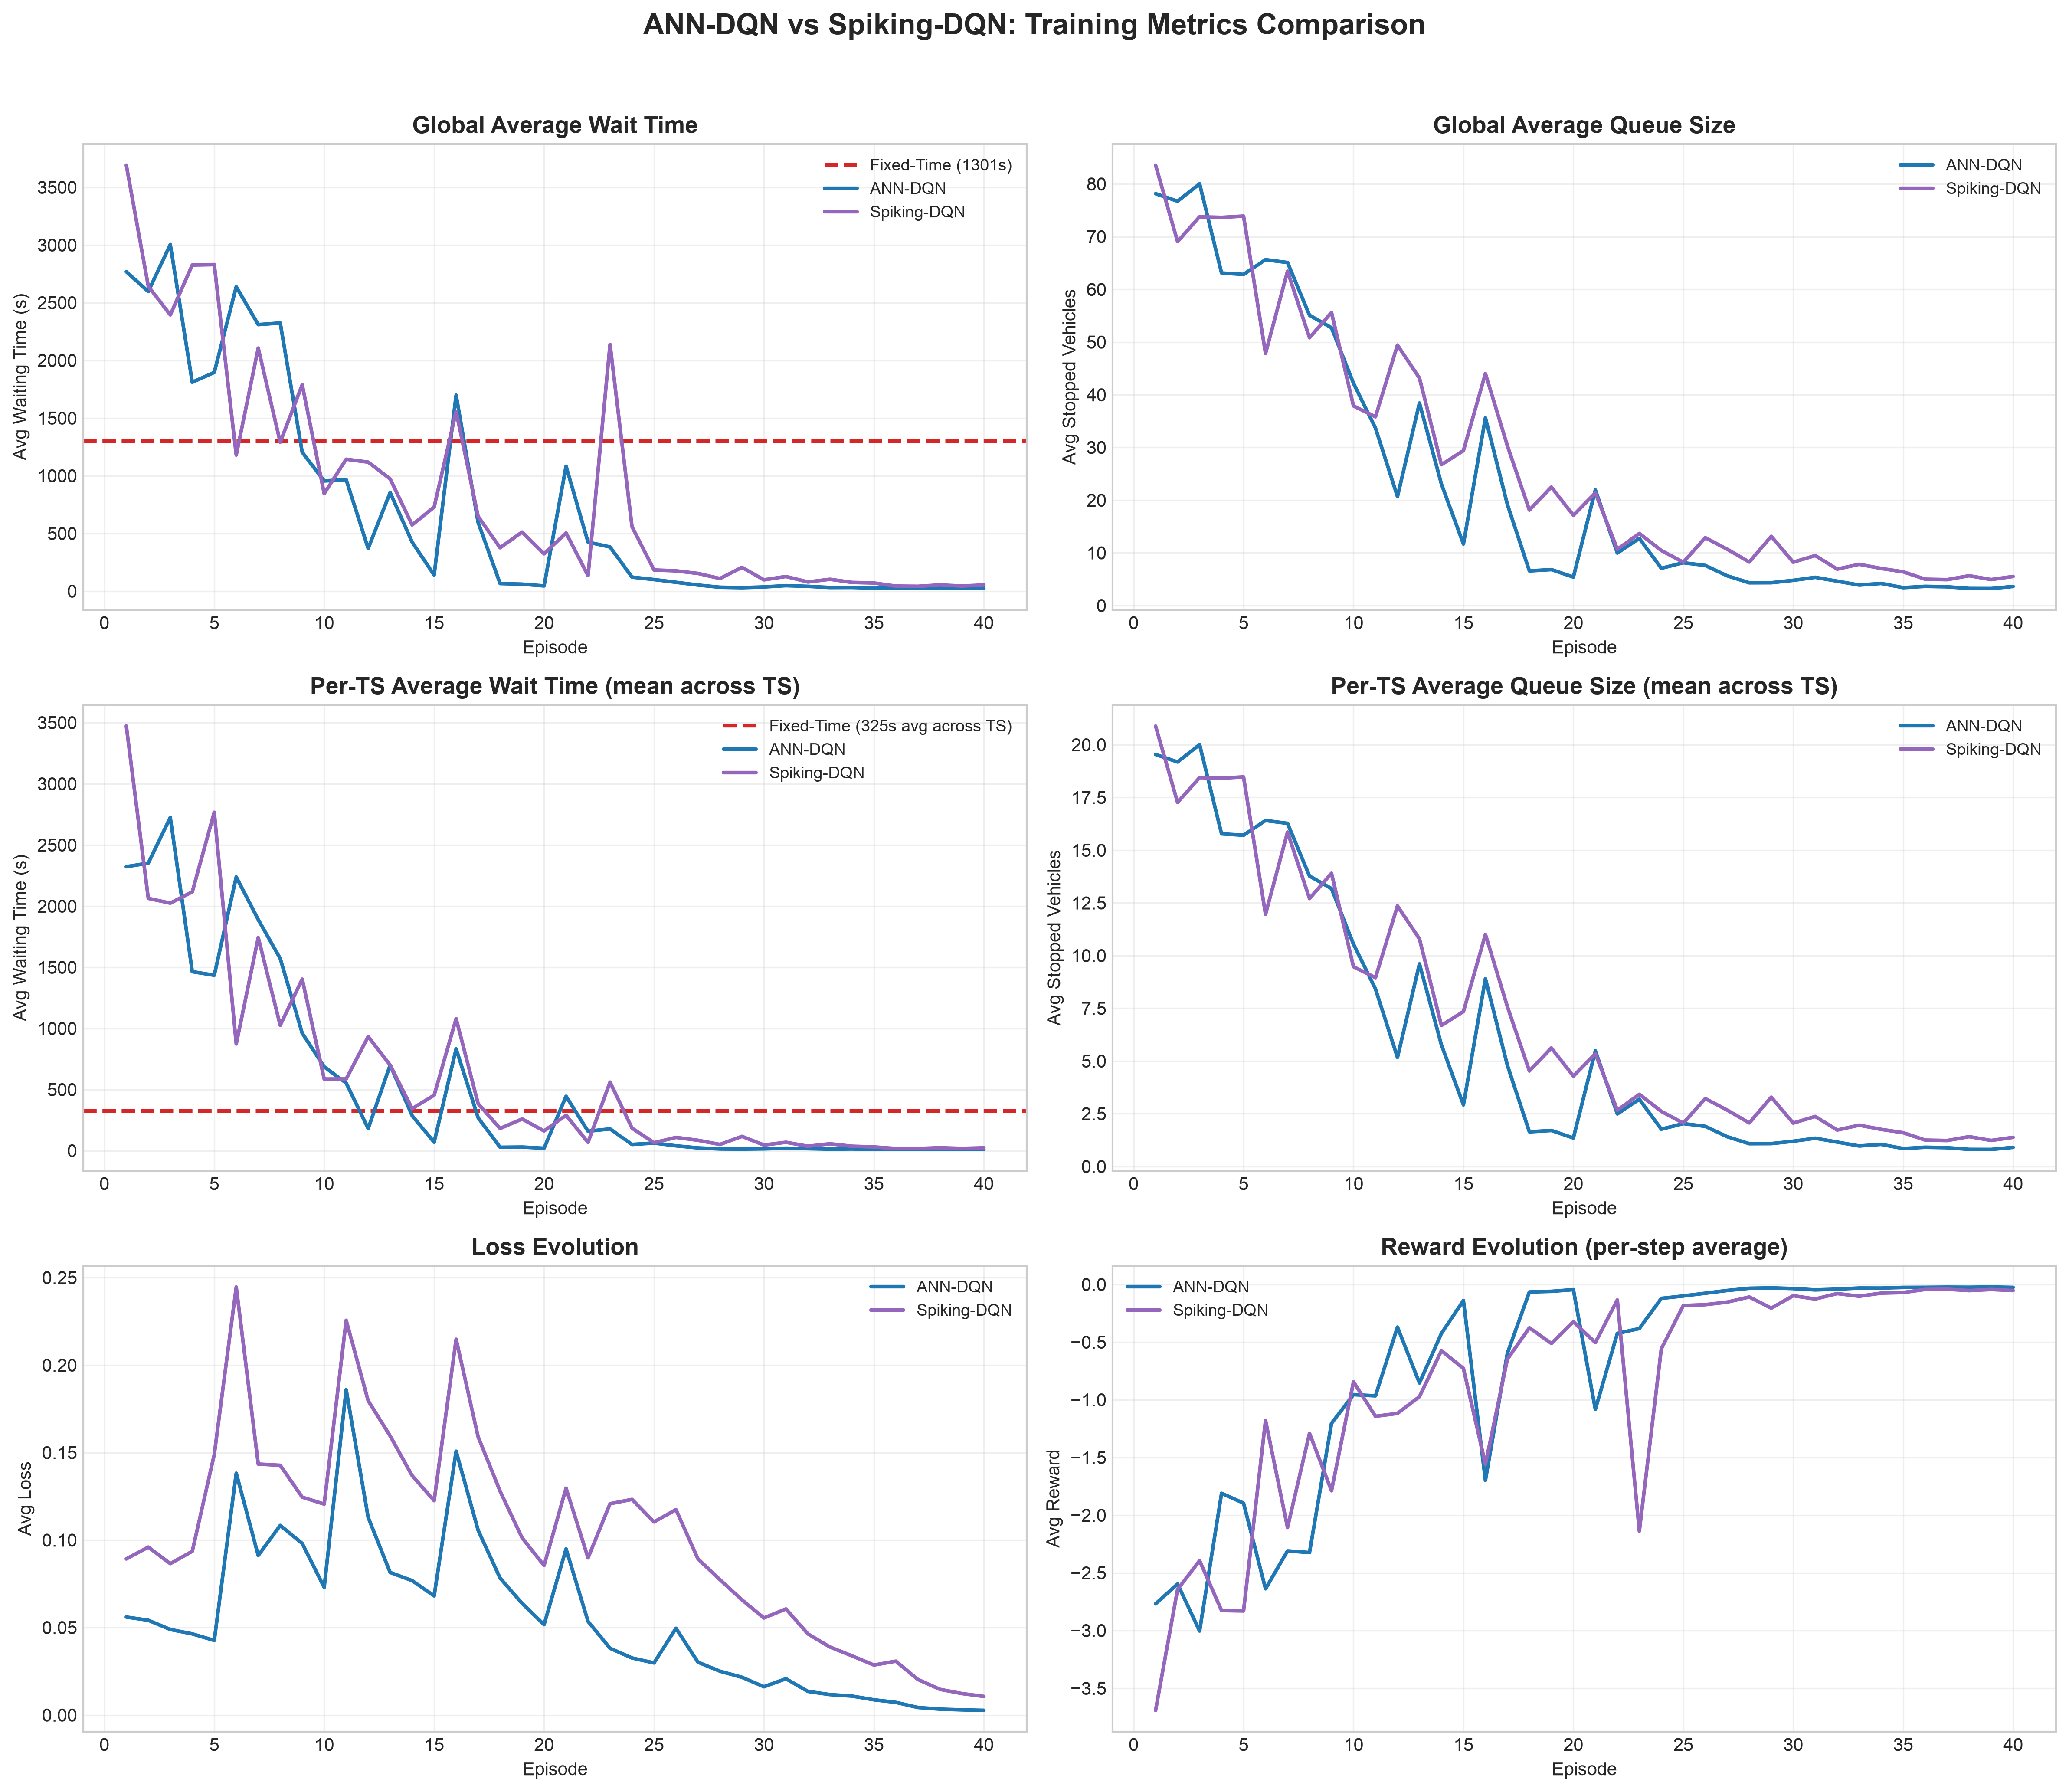

In [15]:
# ---------------------------------------------------------------------------
# 1. Computational cost estimates
# ---------------------------------------------------------------------------
ann_macs = (total_obs_dim * cfg.hidden_dim) + (cfg.hidden_dim * cfg.hidden_dim) + (cfg.hidden_dim * total_act_dim)

# SNN: synaptic operations (SynOps) proportional to emitted spikes
avg_spikes_inference = np.mean(snn_spike_history[-5:]) if len(snn_spike_history) > 0 else 0
# SynOps: average spikes per timestep * hidden_dim (only hidden-to-output matters for spikes)
snn_synops = (avg_spikes_inference / snn_agent.num_steps) * cfg.hidden_dim if avg_spikes_inference > 0 else 0

print("\n================= RESULT COMPARISON =================")
print(f"Baseline 1 (Fixed-Time)       | Avg Wait: {fixed_baseline_wt:.2f} s | Cost: 0 Ops")
print(f"Baseline 2 (Classic ANN)      | Avg Wait: {waiting_time_history[-1]:.2f} s | "
      f"Cost: {ann_macs} MACs")
print(f"Proposal   (Spiking-DQN)      | Avg Wait: {snn_waiting_time_history[-1]:.2f} s | "
      f"Cost: ~{int(snn_synops)} SynOps")
print("=====================================================")

# ---------------------------------------------------------------------------
# 2. Comprehensive 2x3 subplot figure
# ---------------------------------------------------------------------------
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, axes = plt.subplots(3, 2, figsize=(16, 14), dpi=300)

episodes = range(1, cfg.episodes + 1)
colors_ann = 'tab:blue'
colors_snn = 'tab:purple'

# --- (0,0): Global Average Wait Time ---
axes[0][0].axhline(y=fixed_baseline_wt, color='tab:red', linestyle='--', linewidth=2,
                   label=f'Fixed-Time ({fixed_baseline_wt:.0f}s)')
axes[0][0].plot(episodes, waiting_time_history, color=colors_ann, linewidth=2, label='ANN-DQN')
axes[0][0].plot(episodes, snn_waiting_time_history, color=colors_snn, linewidth=2, label='Spiking-DQN')
axes[0][0].set_title('Global Average Wait Time', fontsize=13, fontweight='bold')
axes[0][0].set_xlabel('Episode')
axes[0][0].set_ylabel('Avg Waiting Time (s)')
axes[0][0].legend(fontsize=9)
axes[0][0].grid(True, alpha=0.3)

# --- (0,1): Global Average Queue Size ---
axes[0][1].plot(episodes, queue_history, color=colors_ann, linewidth=2, label='ANN-DQN')
axes[0][1].plot(episodes, snn_queue_history, color=colors_snn, linewidth=2, label='Spiking-DQN')
axes[0][1].set_title('Global Average Queue Size', fontsize=13, fontweight='bold')
axes[0][1].set_xlabel('Episode')
axes[0][1].set_ylabel('Avg Stopped Vehicles')
axes[0][1].legend(fontsize=9)
axes[0][1].grid(True, alpha=0.3)

# --- (1,0): Per-TS Average Wait Time (averaged across TS) ---
ann_per_ts_avg = np.mean([per_ts_waiting_time_history[ts_id] for ts_id in ts_ids_sorted], axis=0)
snn_per_ts_avg = np.mean([snn_per_ts_waiting_time_history[ts_id] for ts_id in ts_ids_sorted], axis=0)
axes[1][0].axhline(y=fixed_baseline_wt / num_agents, color='tab:red', linestyle='--', linewidth=2,
                   label=f'Fixed-Time ({fixed_baseline_wt/num_agents:.0f}s avg across TS)')
axes[1][0].plot(episodes, ann_per_ts_avg, color=colors_ann, linewidth=2, label='ANN-DQN')
axes[1][0].plot(episodes, snn_per_ts_avg, color=colors_snn, linewidth=2, label='Spiking-DQN')
axes[1][0].set_title('Per-TS Average Wait Time (mean across TS)', fontsize=13, fontweight='bold')
axes[1][0].set_xlabel('Episode')
axes[1][0].set_ylabel('Avg Waiting Time (s)')
axes[1][0].legend(fontsize=9)
axes[1][0].grid(True, alpha=0.3)

# --- (1,1): Per-TS Average Queue Size (averaged across TS) ---
ann_per_ts_q_avg = np.mean([per_ts_queue_history[ts_id] for ts_id in ts_ids_sorted], axis=0)
snn_per_ts_q_avg = np.mean([snn_per_ts_queue_history[ts_id] for ts_id in ts_ids_sorted], axis=0)
axes[1][1].plot(episodes, ann_per_ts_q_avg, color=colors_ann, linewidth=2, label='ANN-DQN')
axes[1][1].plot(episodes, snn_per_ts_q_avg, color=colors_snn, linewidth=2, label='Spiking-DQN')
axes[1][1].set_title('Per-TS Average Queue Size (mean across TS)', fontsize=13, fontweight='bold')
axes[1][1].set_xlabel('Episode')
axes[1][1].set_ylabel('Avg Stopped Vehicles')
axes[1][1].legend(fontsize=9)
axes[1][1].grid(True, alpha=0.3)

# --- (2,0): Loss Evolution ---
axes[2][0].plot(episodes, loss_history, color=colors_ann, linewidth=2, label='ANN-DQN')
axes[2][0].plot(episodes, snn_loss_history, color=colors_snn, linewidth=2, label='Spiking-DQN')
axes[2][0].set_title('Loss Evolution', fontsize=13, fontweight='bold')
axes[2][0].set_xlabel('Episode')
axes[2][0].set_ylabel('Avg Loss')
axes[2][0].legend(fontsize=9)
axes[2][0].grid(True, alpha=0.3)

# --- (2,1): Reward Evolution ---
axes[2][1].plot(episodes, reward_history, color=colors_ann, linewidth=2, label='ANN-DQN')
axes[2][1].plot(episodes, snn_reward_history, color=colors_snn, linewidth=2, label='Spiking-DQN')
axes[2][1].set_title('Reward Evolution (per-step average)', fontsize=13, fontweight='bold')
axes[2][1].set_xlabel('Episode')
axes[2][1].set_ylabel('Avg Reward')
axes[2][1].legend(fontsize=9)
axes[2][1].grid(True, alpha=0.3)

fig.suptitle('ANN-DQN vs Spiking-DQN: Training Metrics Comparison', fontsize=16, fontweight='bold', y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig(cfg.comparison_plot_path)
plt.show()

---
## Latency Benchmark (CPU Only)

Compare inference latency on CPU, since traffic light controllers are embedded systems without GPUs.
Both models are temporarily moved to CPU for a fair comparison.

In [14]:
cpu_device = torch.device("cpu")

# Move models to CPU for a fair comparison (traffic lights don't have GPUs)
agent_cpu = agent.policy_net.to(cpu_device)
snn_agent_cpu = snn_agent.policy_net.to(cpu_device)

dummy_state = torch.randn(1, total_obs_dim)

# Warm up
for _ in range(50):
    _ = agent_cpu(dummy_state)
    _ = snn_agent_cpu(dummy_state)

# 1. Measure ANN latency (1000 iterations)
start_time = time.perf_counter()
with torch.no_grad():
    for _ in range(1000):
        _ = agent_cpu(dummy_state)
ann_latency = (time.perf_counter() - start_time) / 1000 * 1000  # milliseconds

# 2. Measure SNN latency (1000 iterations)
start_time = time.perf_counter()
with torch.no_grad():
    for _ in range(1000):
        _, _ = snn_agent_cpu(dummy_state)
snn_latency = (time.perf_counter() - start_time) / 1000 * 1000  # milliseconds

# Move models back to original device for subsequent cells
agent.policy_net.to(device)
snn_agent.policy_net.to(device)

print(f"ANN Latency (CPU): {ann_latency:.4f} ms per inference")
print(f"SNN Latency (CPU): {snn_latency:.4f} ms per inference")

ANN Latency (CPU): 0.0164 ms per inference
SNN Latency (CPU): 1.3250 ms per inference


---
## Summary

| Method | Avg Waiting Time | Estimated Cost |
|--------|----------------:|:---------------|
| Fixed-Time | 1301.03s | 0 Ops |
| ANN-DQN | 25.94s | 29184 MACs |
| Spiking-DQN (SNN) | 53.33s | ~1429 SynOps |

The Spiking-DQN achieves competitive performance on the 2x2 grid while potentially reducing computational energy consumption through event-driven spike-based computation, making it suitable for low-power edge deployment.